# Masked Autoencoders

Convolutional neural networks (CNNs) have been the dominant architecture for computer vision tasks for many years.
Recently, however, with the introduction of vision transformers (ViTs), CNNs are being replaced in many areas.
ViTs are equipped with the _self-attention mechanism_ (which we will learn more about in the practical), allowing them to model global relationships within an image more effectively.

_Self-supervised learning (SSL)_ provides a viable alternative to supervised learning by allowing a model to learn useful representations from _unlabeled data_, removing the need for costly annotations (such as in the medical domain) and often leading to better representations than those learned through supervised learning.
In the case of masked autoencoders (MAE), the model is trained to reconstruct missing portions of an image.


In this practical, you'll learn how to implement a vision transformer, and use it as the backbone to implement a masked autoencoder (MAE)—one of the most popular self-supervised learning (SSL) methods.

Since MAE mainly uses vision transformers (ViT) as its backbone, we'll begin by building a simple vision transformer and then proceed to implement MAE.

Useful resources:
1. [Masked Autoencoders Are Scalable Vision Learners](https://arxiv.org/abs/2111.06377)
2. [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929)


**Colab instructions:** select *Runtime → Change runtime type → GPU* (a T4 is enough), then run the notebook from top to bottom.
PyTorch and torchvision are preinstalled on Colab, so no installation is needed; CIFAR-10 downloads automatically.

All TODOs are implemented. The written answers explain the concepts; where an answer depends on the experiment, the notebook prints a table or shows figures that you should check against the text after your own run.
Training takes most of the time: the main MAE run (20 epochs, about 1.5 h on a T4) and the two positional-encoding variants (10 epochs each by default).
Checkpoints are written to `output_dir`. Colab deletes local files when the runtime is recycled; to keep them, mount Google Drive and point `output_dir` at a Drive folder (see the comment in the next code cell).
Download the executed notebook with **File → Download → Download .ipynb** when you are done.

## Import packages

In [1]:
import datetime
import time
from functools import partial
import os
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
import torchvision.transforms as transforms
import torchvision
from torchvision.transforms import InterpolationMode

notebook_started_at = time.time()  # used for the timing question at the end

data_path = './data/CIFAR10'
output_dir = './output_dir/tmp'
# To keep checkpoints across Colab sessions, uncomment the next lines:
# from google.colab import drive; drive.mount('/content/drive')
# output_dir = '/content/drive/MyDrive/dd2412_mae/tmp'
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'  # cpu is fine for the unit tests, not for training
print('Using device:', device)

Using device: cuda:0


## Patchifying an image


Vision transformers process images as a sequence of patches, much like how traditional transformers in natural language processing handle sequences of words.
In this case, instead of words, the model works with image patches. These patches are essentially non-overlapping $p \times p$ grids extracted from the original image.

Below we visulize what happens when an image is converted to patches, to get a better understanding of it.

In [2]:
def patchify(patch_size: int, imgs: torch.Tensor, flatten_channels: bool =True):
    """
        This function receives a batch of images and transform each image into patches.
        - patch_size: size of the square patches into which the input image is divided
        - imgs: (N, 3, H, W)
        - x: (N, L, patch_size**2 *3)
    """
    p = patch_size
    assert imgs.shape[2] == imgs.shape[3] and imgs.shape[2] % p == 0

    h = w = imgs.shape[2] // p
    x = imgs.reshape(shape=(imgs.shape[0], 3, h, p, w, p))
    x = torch.einsum('nchpwq->nhwpqc', x)
    if flatten_channels:
        x = x.reshape(shape=(imgs.shape[0], h * w, p**2 * 3))  # (N, L, p**2 *3), for model training
    else:
        x = x.reshape(shape=(imgs.shape[0], h * w, p, p, 3))  # (N, L, p, p, 3), for visualization
    return x

For illustration, we use a large patch size to better understand the mechanism, but in ViT a smaller patch size is typically used.




100%|██████████| 170M/170M [1:07:02<00:00, 42.4kB/s] 


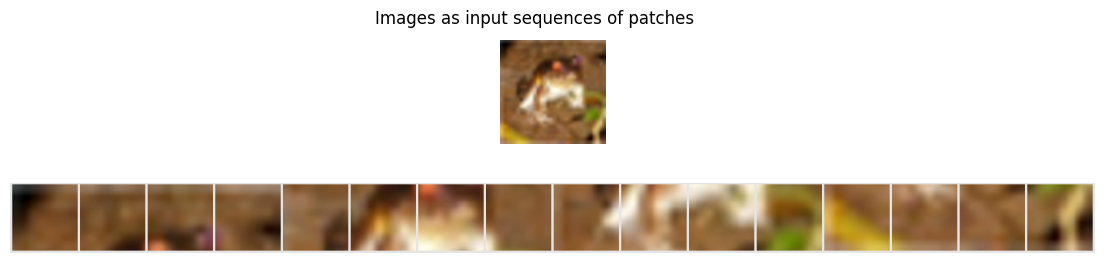

In [3]:
img_size = 224
psize = 56  # divide the img into patches of this size (you can play aroud with different numbers)
assert img_size % psize == 0, 'img size should be divisble by patch size!'

dataset_test = torchvision.datasets.CIFAR10(root=data_path, train=True, transform=None, download=True)
orig_img, label = dataset_test[0]
orig_img = orig_img.resize((img_size, img_size))

img = torch.Tensor(np.array(orig_img))  # (224, 224, 3)
# make it like a mini-batch of size B=1 - (1, 224, 224, 3), since the function expects a batch
img = img.unsqueeze(dim=0)
# use einsum for permutation of tensor dims (B, H, W, C) --> (B, C, H, W), as the function expects
img = torch.einsum('nhwc->nchw', img)
patches = patchify(patch_size=psize, imgs=img, flatten_channels=False)
patches = patches.squeeze(dim=0)  # extract the single img

# make a grid and visualize
img_grid = torchvision.utils.make_grid(tensor=torch.einsum('lpqc -> lcpq', patches), nrow=patches.shape[0], normalize=True, pad_value=0.9)
img_grid = torch.einsum('chw -> hwc', img_grid)  # imshow expects shape (H, W, C)

fig, ax = plt.subplots(2, 1, figsize=(14, 3))
fig.suptitle("Images as input sequences of patches")

# display the image
ax[0].imshow(orig_img)
ax[1].imshow(img_grid)

ax[0].axis('off')
ax[1].axis('off')

plt.show()
plt.close()

## Vision Transformer (ViT)

### Patch Embedding

To enhance the versatility of ViT representations, the patchification process in Vision Transformers (ViTs) is typically implemented using a trainable module.
This module learns to map image patches to "tokens," which are vector representations of each patch.

This mapping is achieved through a convolutional operation that transforms each patch of size ($c \times p \times p$) into a token of shape (`embed_dim`$\times 1$).
Here, `embed_dim` represents the dimension of each token, with larger values allowing for more expressive representations of each patch.

Below, we implement this module

In [4]:
class PatchEmbed(nn.Module):
    """ Image to Patch Embedding
    """
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=384):
        super().__init__()
        num_patches = (img_size // patch_size) * (img_size // patch_size)
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = num_patches
        self.embed_dim = embed_dim

        # convert patches to tokens in a learnable way
        # for simplicity we use stride=patch_size so the patches are non-overlapping
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size, bias=True)

    def forward(self, x):
        """
        TODO: Implement operation to convert patches to tokens
            - x: a batch of images with shape (B, C, H, W)
            - output: a batch of tokens, representing image patches with shape (B, L, D),
            where L is the number of tokens (sequence length), and D is embed_dim
        """
        B, C, H, W = x.shape
        assert H == self.img_size and W == self.img_size, \
            f'Input size ({H}x{W}) does not match the model ({self.img_size}x{self.img_size})'
        x = self.proj(x)                  # (B, D, H/p, W/p): one D-dim token per patch
        x = x.flatten(2).transpose(1, 2)  # (B, D, L) -> (B, L, D), row-major patch order
        return x



# test the implementation of patch embeddings
bsize, in_channels, img_size = 16, 3, 224
psize = 16  # patch_size
embed_dim = 384
inp = torch.randn(size=(bsize, in_channels, img_size, img_size))  # a batch of images with size (B, C, H, W)
embedder = PatchEmbed(img_size=img_size, patch_size=psize, in_chans=in_channels, embed_dim=embed_dim)
out = embedder(inp)
n_patches = 196  # (224 / 16) ** 2
assert embedder.num_patches == n_patches, f'Number of patches {embedder.num_patches} does not meet the expected value!'
assert out.shape == (bsize, n_patches, embed_dim), f'The embedding shape {out.shape} does not match the expected value!'

### Multi-Head Attention

The attention mechanism is the key part of transformers that helps the model focus on different parts of the input when making predictions. Think of it like reading a sentence: to understand a particular word, you look at the other words around it to get the full meaning. Similarly, attention helps the model understand the context better by determining which words (or tokens) are more relevant.

To achieve this, the model uses a specific method called *dot-product attention*.
Essentially, attention can be thought of as a way to map a query to a set of key-value pairs.
This method involves three components: query $q$, key $k$, and value $v$, each representing a token.

In practice, we calculate the attention for a set of queries, keys, and values at once by arranging them into a matrix $Q$, $K$, and $V$ respectively.
When $Q$, $K$, and $V$ are coming from the same set of tokens, it is called "self-attention".


To enhance the versatility of the representations, tokens are first transformed using linear transformations.
\begin{equation*}
Q = QW^Q, \quad K = KW^K, \quad V = VW^V
\end{equation*}
where Here, $W^Q$, $W^K$, and $W^V$ are learnable projections matrices that linearly transform $d$-dimensional tokens (to the same dimension $d$).
Following this transformation, attention can be computed on the set of transformed matrices:
\begin{equation*}
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d}}\right)V
\end{equation*}
The output of $\text{softmax}\left(\frac{QK^T}{\sqrt{d}}\right)$ is basically an $N \times N$ attention matrix A (for $N$ tokens) where each entry $A_{ij}$ denotes the _compatibility_ between token $q_i$ and $k_j$.

As can be seen, this operation essentially calculates the weighted sum of the values $V$, where the weight assigned to each value is determined by the compatibility of the queries $Q$ with the corresponding keys $K$.
This allows the model to capture long-range relationships within an image, enabling the model to effectively integrate information across different parts of the image.


In practice, however, a single attention head may be limited in its capacity to capture diverse semantic meanings within an image.
To overcome this, the Transformer introduces _multi-head attention_, where multiple "attention heads" are used in parallel to calculate attention in different representation subspaces.

Let $h$ denote the number of heads. Instead of performing a single attention function with $d$-dimensional keys, values and query tokens are divided into smaller $d_h$-dimensional tokens, where $d_h \times h = d$.
We denote the resuling matrices for each $\text{head}_i$ as $Q_i$, $K_i$, and $V_i$.

Now the attention is computed for each subspace individually (each resulting in its own attention matrix $A_i$):
\begin{equation*}
\text{head}_i = \text{Attention}(Q_i, K_i, V_i) = \text{softmax}\left(\frac{Q_iK_i^T}{\sqrt{d_h}}\right)V_i
\end{equation*}
Finally, the outputs from multuple heads are concatenated together and integrated through a linear transformation with $W^O$.

\begin{equation*}
\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, \ldots, \text{head}_h) W^O
\end{equation*}


Below, we implement the attention mechanism.

In [5]:
class Attention(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5  # helps with the gradients, read more here: https://arxiv.org/abs/1706.03762

        # in practice it is common to use a single linear layer to obtain q, k, v projections
        self.qkv = nn.Linear(dim, dim * 3, bias=True)  # W^Q, W^K, W^V
        self.proj = nn.Linear(dim, dim)  # W^O

    def forward(self, x):
        """
            TODO: implement multi-head self-attention.
        """
        B, N, C = x.shape
        head_dim = C // self.num_heads
        # one linear layer gives q, k, v; split them and the heads:
        # (B, N, 3C) -> (B, N, 3, h, C/h) -> (3, B, h, N, C/h)
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]               # each (B, h, N, d_h)
        attn = (q @ k.transpose(-2, -1)) * self.scale  # (B, h, N, N): Q_i K_i^T / sqrt(d_h)
        attn = attn.softmax(dim=-1)                    # each row sums to 1 over the keys
        out = attn @ v                                 # (B, h, N, d_h): weighted sum of values
        out = out.transpose(1, 2).reshape(B, N, C)     # concatenate the heads
        out = self.proj(out)                           # W^O
        return out, attn  # out: transformed tokens, attn: attention scores



# test the implementation of multi-head self-attention
bsize, n_tokens = 16, 196  # batch size: 16, num of tokens per image: 196
dim, num_heads = 384, 6

inp = torch.randn(size=(bsize, n_tokens, dim))
multi_head_attention = Attention(dim=dim, num_heads=num_heads)
out, attn = multi_head_attention(inp)

assert out.shape == (bsize, n_tokens, dim), f'Output shape {out.shape} does not match the expected value!'
assert attn.shape == (bsize, num_heads, n_tokens, n_tokens), f'Attention matrix shape {attn.shape} does not match the expected value!'
# extra check: every attention row is a probability distribution over the tokens
assert torch.allclose(attn.sum(-1), torch.ones(bsize, num_heads, n_tokens), atol=1e-5)
print('Attention tests passed.')

Attention tests passed.


### MLP layers
Transformers also use MLP layers after the attention mechanism. An MLP generally consists of two linear transformations with a non-linear activation function in between.
Unlike attention, which handles interactions between tokens, the MLP layer transforms each token independently, enhancing its expressiveness.
This is critical to make tokens expressive enough and to enable the model to learn diverse attention patterns (read more [here](https://arxiv.org/abs/2103.03404) if you are interested)



Below, we implement this layer.

In [6]:
class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features):
        super().__init__()
        out_features = in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, out_features)

    def forward(self, x):
        """
            TODO: implement the forward function of MLP: two linear operation
            with a non-linearity in between.
        """
        return self.fc2(self.act(self.fc1(x)))



# test MLP implementation
bsize, n_tokens = 16, 196
dim = 384
hidden_dim = 4 * dim  # feature dim is increased by fc1 and decreased back to original dim by fc2

inp = torch.randn(size=(bsize, n_tokens, dim))
mlp_module = Mlp(in_features=dim, hidden_features=hidden_dim)
out = mlp_module(inp)

assert out.shape == (bsize, n_tokens, dim), f'Output shape {out.shape} does not match the expected value!'

### Block
Now that we have implemented the Attention and MLP modules, we can move on to implementing the blocks of the Vision Transformer (provided below).
Each block consists of an Attention module followed by an MLP module, both equipped with residual connections.
Layer normalization is applied before each module to stabalize training and improve performance.

In [7]:
class Block(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim, num_heads=num_heads)
        self.norm2 = nn.LayerNorm(dim)
        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = Mlp(in_features=dim, hidden_features=mlp_hidden_dim)

    def forward(self, x, return_attention=False):
        y, attn = self.attn(self.norm1(x))
        x = x + y
        x = x + self.mlp(self.norm2(x))
        if return_attention:
            return x, attn
        return x

## Masked autoencoder

The primary goal of MAE is to learn meaningful representations from unlabelled data by reconstructing the the signal its partial observation.
This is achieved using two asymmetric networks: an **encoder** ViT that maps the observed portion of the image to a latent representation, and a lightweight **decoder** ViT, which reconstructs the original signal from this latent representation.

First, an image is **masked** to obtain a small portion of the patches, with the masking ratio typically set to a high value (e.g. 75%).
This approach makes the reconstruction task more challenging for the network, which is crucial for learning more meaningful representations.

The encoder processes only the visible (unmasked) patches and generates latent representations for those patches.
More specifically, as with a standard ViT, the encoder projects patches using a linear transformation to create tokens, adds positional embeddings, and processes the resulting sequence through a series of encoder transformer blocks.

The decoder receives the full set of tokens, including both the encoded visible patches and __mask tokens__.
Each mask token is a shared, learned vector that indicates the presence of a missing patch to be predicted by the decoder.
Positional embeddings are added for all tokens, and the sequence is passed through a series of decoder transformer blocks.
Finally, the decoder linearly projects the tokens back to predict patch pixels.

The final loss is computed as the mean squared error (MSE) between the reconstructed and original image patches in the pixel space, and is only computed for the masked patches.

Below we implement MAE.

In [8]:
def random_masking(x, mask_ratio):
    """
        Helper function to perform random masking and sampling visible tokens.
        Perform per-sample random masking by per-sample shuffling.
        Per-sample shuffling is done by argsort random noise.
        Make sure to read the implementation carefully and understand it, as it is the
        core function used for masking and reconstruction.

        x: [N, L, D], sequence
        retrurns:
            - x_masked: the portion of the visible patches
            - mask: image binary mask -- 0 is keep, 1 is remove
            - ids_restore: the actual location of the suffled patches, used by decoder for re-ordering patches
    """
    N, L, D = x.shape  # batch, length, dim
    len_keep = int(L * (1 - mask_ratio))

    noise = torch.rand(N, L, device=x.device)  # noise in [0, 1]

    # sort noise for each sample
    ids_shuffle = torch.argsort(noise, dim=1)  # ascend: small is keep, large is remove
    ids_restore = torch.argsort(ids_shuffle, dim=1)  # actual patch locations

    # keep the first subset
    ids_keep = ids_shuffle[:, :len_keep]
    x_masked = torch.gather(x, dim=1, index=ids_keep.unsqueeze(-1).repeat(1, 1, D))

    # generate the binary mask: 0 is keep, 1 is remove
    mask = torch.ones([N, L], device=x.device)
    mask[:, :len_keep] = 0
    # unshuffle to get the binary mask
    mask = torch.gather(mask, dim=1, index=ids_restore)

    return x_masked, mask, ids_restore


class MaskedAutoencoderViT(nn.Module):
    """ Masked Autoencoder with VisionTransformer backbone
    """
    def __init__(self, img_size=224, patch_size=16, in_chans=3,
                 embed_dim=1024, depth=24, num_heads=16, mlp_ratio=4.,
                 decoder_embed_dim=512, decoder_depth=8, decoder_num_heads=16):
        super().__init__()

        # encoder
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim), requires_grad=True)

        self.blocks = nn.ModuleList([
            Block(embed_dim, num_heads, mlp_ratio)
            for _ in range(depth)]
        )
        self.norm = nn.LayerNorm(embed_dim)

        # decoder
        self.decoder_embed = nn.Linear(embed_dim, decoder_embed_dim, bias=True)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, decoder_embed_dim))
        self.decoder_pos_embed = nn.Parameter(torch.zeros(1, num_patches, decoder_embed_dim), requires_grad=True)

        self.decoder_blocks = nn.ModuleList([
            Block(decoder_embed_dim, decoder_num_heads, mlp_ratio)
            for _ in range(decoder_depth)]
        )

        self.decoder_norm = nn.LayerNorm(decoder_embed_dim)
        self.decoder_pred = nn.Linear(decoder_embed_dim, patch_size**2 * in_chans, bias=True) # decoder to patch
        self.initialize_weights()

    def initialize_weights(self):
        w = self.patch_embed.proj.weight.data
        torch.nn.init.xavier_uniform_(w.view([w.shape[0], -1]))
        torch.nn.init.normal_(self.pos_embed, std=.02)
        torch.nn.init.normal_(self.decoder_pos_embed, std=.02)
        torch.nn.init.normal_(self.mask_token, std=.02)
        # initialize nn.Linear and nn.LayerNorm
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            torch.nn.init.xavier_uniform_(m.weight)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.0)

    def forward(self, imgs, mask_ratio=0.75, return_attention=False):
        """
            The forward function of the MAE is implemented for you.
            Below we implement individual forwad components.
        """
        if return_attention:
            latent, mask, ids_restore, attn = self.forward_encoder(imgs, mask_ratio, return_attention=True)
        else:
            latent, mask, ids_restore = self.forward_encoder(imgs, mask_ratio)
        pred = self.forward_decoder(latent, ids_restore)  # [N, L, p*p*3]
        loss = self.forward_loss(imgs, pred, mask)
        if return_attention:
            return loss, pred, mask, attn
        return loss, pred, mask

    def forward_encoder(self, x, mask_ratio, return_attention=False):
        """
            TODO: implement encoder forward.
            This takes all the tokens, randomly mask a large portion of the tokens
            and produced latent
        """
        # generate patch embeddings (tokens)
        x = self.patch_embed(x)                                   # (B, L, D)
        # add positional embeddings (self.pos_embed) to the tokens
        x = x + self.pos_embed                                    # before masking, so kept tokens keep their position
        # masking: length -> length * (1 - mask_ratio)
        x, mask, ids_restore = random_masking(x, mask_ratio)      # (B, L_keep, D)
        # pass the visible (unmasked) tokens through the encoder blocks
        attn = None
        for blk in self.blocks:
            if return_attention:
                x, attn = blk(x, return_attention=True)           # keep the last block's attention
            else:
                x = blk(x)
        # apply encoder layer norm
        x = self.norm(x)
        if return_attention:
            return x, mask, ids_restore, attn
        return x, mask, ids_restore
    def forward_decoder(self, x, ids_restore):
        """
            TODO: implement decoder forward.
            This takes the latent representation produced by the encoder, incorporate mask tokens
            and reconstruct the masked patches.
            - x: latent representation (tokens) produced by the encoder from the visible patches
            - ids_restore: the token ids to be used to unshuffle tokens
        """
        # generate decoder token embeddings
        x = self.decoder_embed(x)                                 # (B, L_keep, D_dec)
        # append one copy of the shared mask token for every missing patch
        B, L_keep, D = x.shape
        L = ids_restore.shape[1]
        mask_tokens = self.mask_token.repeat(B, L - L_keep, 1)    # (B, L - L_keep, D_dec)
        x = torch.cat([x, mask_tokens], dim=1)                    # still in shuffled order
        # unshuffle: position j receives token ids_restore[:, j]
        x = torch.gather(x, dim=1, index=ids_restore.unsqueeze(-1).repeat(1, 1, D))  # (B, L, D_dec)
        # add pos embed (self.decoder_pos_embed)
        x = x + self.decoder_pos_embed
        # apply decoder transformer blocks
        for blk in self.decoder_blocks:
            x = blk(x)
        # apply decoder final layer norm
        x = self.decoder_norm(x)
        # apply predictor projection to predict the reconstructed pixels with shape (B, N, p*p*3)
        x = self.decoder_pred(x)
        return x
    def forward_loss(self, imgs, pred, mask):
        """
            TODO: implement the mean squared loss between the imgs and the reconstructed pixels.
            imgs: (B, 3, H, W)
            pred: (B, N, p*p*3)
            mask: (B, N), 0 denotes keep, 1 denotes remove
        """
        # patchify the imgs using the function we defined earlier in the notebook
        target = patchify(patch_size=self.patch_embed.patch_size, imgs=imgs)  # (B, N, p*p*3)
        # per-patch MSE, then average only over the masked (removed, mask == 1) patches,
        # as in the MAE paper: visible patches are not part of the reconstruction loss
        loss = ((pred.float() - target.float()) ** 2).mean(dim=-1)            # (B, N)
        loss = (loss * mask).sum() / mask.sum()
        return loss



# build MAE
def build_model(**kwargs):
    model = MaskedAutoencoderViT(
        patch_size=16, embed_dim=384, depth=12, num_heads=6,
        decoder_embed_dim=512, decoder_depth=8, decoder_num_heads=16,
        mlp_ratio=4, **kwargs)
    return model

In [9]:
# sanity checks for the MAE implementation (small CPU forward pass)
_m = build_model(img_size=224)
_x = torch.randn(2, 3, 224, 224)
_loss, _pred, _mask = _m(_x, mask_ratio=0.75)
assert _pred.shape == (2, 196, 16 * 16 * 3), _pred.shape
assert _mask.shape == (2, 196) and torch.all(_mask.sum(1) == 196 - int(196 * 0.25))
assert _loss.ndim == 0 and torch.isfinite(_loss)
# the loss must ignore visible patches: copying the target into the visible positions does not change it
_target = patchify(16, _x)
_pred_vis = torch.where(_mask.unsqueeze(-1).bool(), _pred, _target)
assert torch.allclose(_m.forward_loss(_x, _pred_vis, _mask), _loss)
# a perfect prediction on the masked patches gives zero loss
assert _m.forward_loss(_x, _target, _mask).item() < 1e-10
print(f'MAE tests passed. Parameters: {sum(p.numel() for p in _m.parameters()) / 1e6:.1f} M')
del _m, _x, _loss, _pred, _mask, _target, _pred_vis

MAE tests passed. Parameters: 47.6 M


## Training
Below we do the actual training.
Training an MAE is efficient thanks to the high portion of masked patches that the encoder does not process, but still requires long training in order to learn rich representations.
We train the MAE for several epochs below and save checkpoints to visualize model reconstructions.
The default number of checkpoints below is set to 20, which should take ~1.5h on Colab, but it might be a good idea to decrease it when beginning and visualize the trained model to make sure the implementation works as intended. Even after a few epochs you should be able to see some meaningful reconstructions.

Start training for 20 epochs -> ./output_dir/tmp


Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 1 done. Time: 4.221m - mean train loss: 0.771 (last batch 0.384). Saved model checkpoint to: ./output_dir/tmp/checkpoint-1.pth


Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 2 done. Time: 4.252m - mean train loss: 0.265 (last batch 0.204). Saved model checkpoint to: ./output_dir/tmp/checkpoint-2.pth


... (32 outputs left out)

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 19 done. Time: 4.334m - mean train loss: 0.065 (last batch 0.062). Saved model checkpoint to: ./output_dir/tmp/checkpoint-19.pth


Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 20 done. Time: 4.333m - mean train loss: 0.064 (last batch 0.065). Saved model checkpoint to: ./output_dir/tmp/checkpoint-20.pth
Training time 1:26:16


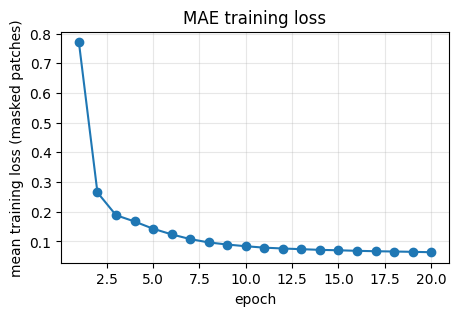

In [10]:
# train config
masking_ratio = 0.75
input_size = 224

batch_size = 64  # this can be increased for faster training, depending on gpu memory size
num_workers = min(4, os.cpu_count() or 2)  # Colab has 2 CPU cores; more workers only produce a warning
lr = 1e-3
pin_mem = torch.cuda.is_available()
epochs = 20
# decrease epochs to e.g. 5 when debugging, you should see meaningful reconstructions
# even after a few epochs if the implementation is correct
save_interval = 1  # intervals to save model checkpoint, feel free to change it
use_amp = torch.cuda.is_available()  # mixed precision only on the GPU

# fix the seed for reproducibility
seed = 0
torch.manual_seed(seed)
np.random.seed(seed)
cudnn.benchmark = True
device = torch.device(device)

# simple augmentation
transform_train = transforms.Compose([
        transforms.RandomResizedCrop(input_size, scale=(0.2, 1.0), interpolation=InterpolationMode.BICUBIC),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
dataset_train = torchvision.datasets.CIFAR10(root=data_path, transform=transform_train, download=True)
data_loader_train = torch.utils.data.DataLoader(
    dataset_train,
    batch_size=batch_size,
    num_workers=num_workers,
    pin_memory=pin_mem,
    drop_last=True,
    shuffle=True
)


def train_mae(model, run_dir, n_epochs, save_interval=save_interval):
    """The provided training loop, wrapped in a function so that the
    positional-encoding variants below are trained in exactly the same way."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model.to(device)
    # only trainable parameters (the fixed positional encodings below are excluded)
    optimizer = torch.optim.AdamW(params=[p for p in model.parameters() if p.requires_grad], lr=lr, betas=(0.9, 0.95))
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    os.makedirs(run_dir, exist_ok=True)
    epoch_losses = []

    print(f"Start training for {n_epochs} epochs -> {run_dir}")
    start_time = time.time()
    epoch_bar = tqdm(range(n_epochs), desc='Epochs', leave=False, total=n_epochs)

    # train loop, we use torch amp for faster training
    for epoch in epoch_bar:
        model.train(True)
        iter_bar = tqdm(data_loader_train, desc='Training', leave=False, total=len(data_loader_train))

        # iterations per epoch
        epoch_start_time = time.time()
        running_loss = 0.0
        for it, (samples, _) in enumerate(iter_bar):
            optimizer.zero_grad()
            samples = samples.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                loss, _, _ = model(samples, mask_ratio=masking_ratio)

            loss_value = loss.item()
            running_loss += loss_value
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            scaler.step(optimizer)
            scaler.update()
        epoch_time = round((time.time() - epoch_start_time) / 60, 3)
        epoch_losses.append(running_loss / (it + 1))

        if (epoch % save_interval == 0 or epoch + 1 == n_epochs):
            checkpoint_path = os.path.join(run_dir, f'checkpoint-{epoch+1}.pth')
            to_save = {
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'epoch': epoch,
                'scaler': scaler.state_dict(),
            }
            torch.save(to_save, checkpoint_path)
            tqdm.write(f'Epoch {epoch+1} done. Time: {epoch_time}m - mean train loss: {epoch_losses[-1]:.3f} '
                       f'(last batch {round(loss_value, 3)}). Saved model checkpoint to: {checkpoint_path}')

    # print time taken
    total_time = time.time() - start_time
    total_time_str = str(datetime.timedelta(seconds=int(total_time)))
    print('Training time {}'.format(total_time_str))
    return epoch_losses


# define the model and train it (learned positional embeddings, as in the provided model)
model = build_model(img_size=input_size)
loss_history = {'learned': train_mae(model, output_dir, epochs)}

plt.figure(figsize=(5, 3))
plt.plot(range(1, epochs + 1), loss_history['learned'], marker='o')
plt.xlabel('epoch'); plt.ylabel('mean training loss (masked patches)')
plt.title('MAE training loss'); plt.grid(alpha=0.3)
plt.show()

## Visualization

Now that we have trained our MAE, we are ready to visualize some images.
Even after 5 epochs of training, we should be able to see meaningful reconstructions, although longer training results in sharper reconstructed images.
Below functions for visualization are provided for you.

In [11]:
# helper functions for visualizing reconstructions from a trained model
def visualize(img, chkpt_dir, mask_ratio, model_builder=None, title=None):
    def unpatchify(patch_size, x):
        """
        x: (N, L, patch_size**2 *3)
        imgs: (N, 3, H, W)
        """
        p = patch_size
        h = w = int(x.shape[1]**.5)
        assert h * w == x.shape[1]

        x = x.reshape(shape=(x.shape[0], h, w, p, p, 3))
        x = torch.einsum('nhwpqc->nchpwq', x)
        imgs = x.reshape(shape=(x.shape[0], 3, h * p, h * p))
        return imgs

    def show_image(image, title=''):
        # image is [H, W, 3]
        assert image.shape[2] == 3
        plt.imshow(torch.clip((image * imagenet_std + imagenet_mean) * 255, 0, 255).int())
        plt.title(title, fontsize=16)
        plt.axis('off')
        return

    @torch.no_grad()
    def run_one_image(img, model):
        x = torch.tensor(img)
        patch_size = model.patch_embed.patch_size

        # make it a batch-like
        x = x.unsqueeze(dim=0)
        x = torch.einsum('nhwc->nchw', x)

        # run MAE
        loss, y, mask = model(x.float(), mask_ratio=mask_ratio)
        y = unpatchify(patch_size=patch_size, x=y)
        y = torch.einsum('nchw->nhwc', y).detach().cpu()

        # visualize the mask
        mask = mask.detach()
        # mask = mask.unsqueeze(-1).repeat(1, 1, model.patch_embed.patch_size[0]**2 *3)  # (N, H*W, p*p*3)
        mask = mask.unsqueeze(-1).repeat(1, 1, model.patch_embed.patch_size**2 *3)  # (N, H*W, p*p*3)
        mask = unpatchify(patch_size=patch_size, x=mask)  # 1 is removing, 0 is keeping
        mask = torch.einsum('nchw->nhwc', mask).detach().cpu()

        x = torch.einsum('nchw->nhwc', x)

        # masked image
        im_masked = x * (1 - mask)

        # MAE reconstruction pasted with visible patches
        im_paste = x * (1 - mask) + y * mask

        # make the plt figure larger
        plt.rcParams['figure.figsize'] = [12, 12] # [24, 24]

        if title is not None:
            plt.suptitle(title, fontsize=16, y=0.62)

        plt.subplot(1, 4, 1)
        show_image(x[0], "original")

        plt.subplot(1, 4, 2)
        show_image(im_masked[0], "masked")

        plt.subplot(1, 4, 3)
        show_image(y[0], "reconstruction")

        plt.subplot(1, 4, 4)
        show_image(im_paste[0], "reconstruction + visible")

        plt.show()

    imagenet_mean = np.array([0.485, 0.456, 0.406])
    imagenet_std = np.array([0.229, 0.224, 0.225])
    img_size = 224
    img = img.resize((img_size, img_size))
    img = np.array(img) / 255.
    assert img.shape == (img_size, img_size, 3)

    # normalize by ImageNet mean and std
    img = img - imagenet_mean
    img = img / imagenet_std

    model_mae = (model_builder or build_model)()
    model_mae.load_state_dict(torch.load(chkpt_dir, map_location='cpu')['model'], strict=True)
    model_mae.eval()
    torch.manual_seed(2)
    run_one_image(img, model_mae)

/tmp/ipykernel_48/1236116758.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.imshow(torch.clip((image * imagenet_std + imagenet_mean) * 255, 0, 255).int())


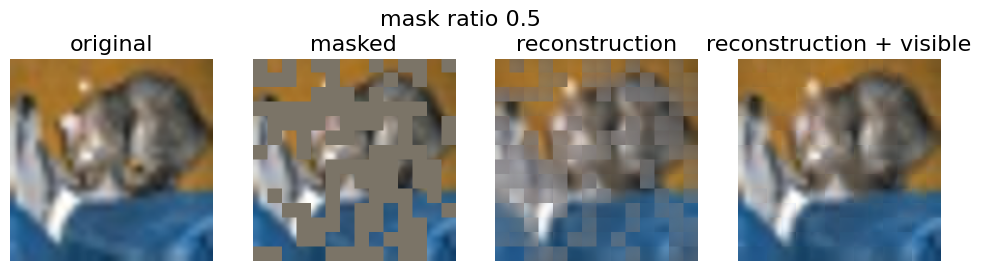

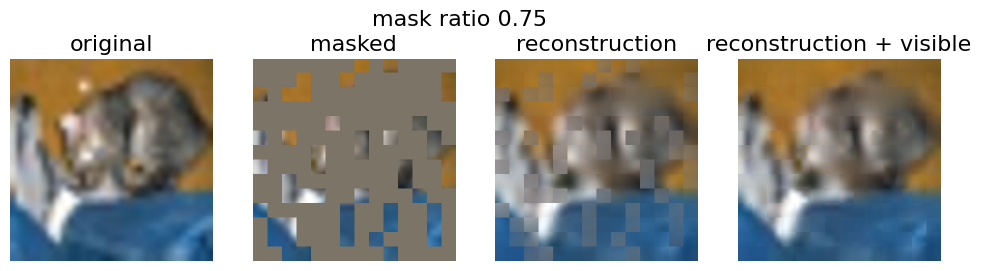

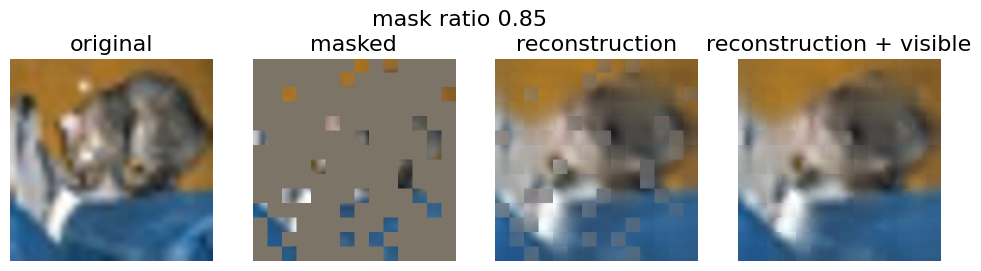

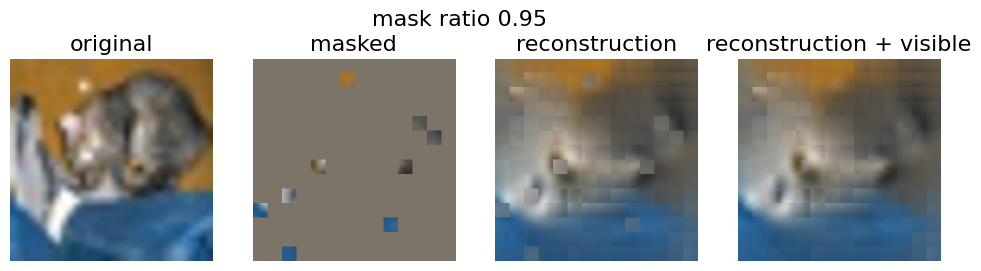

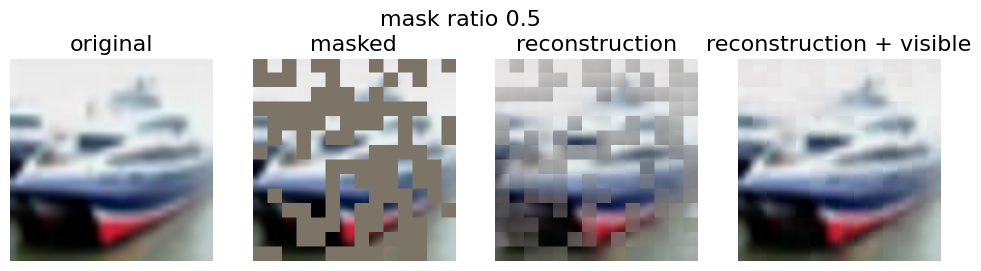

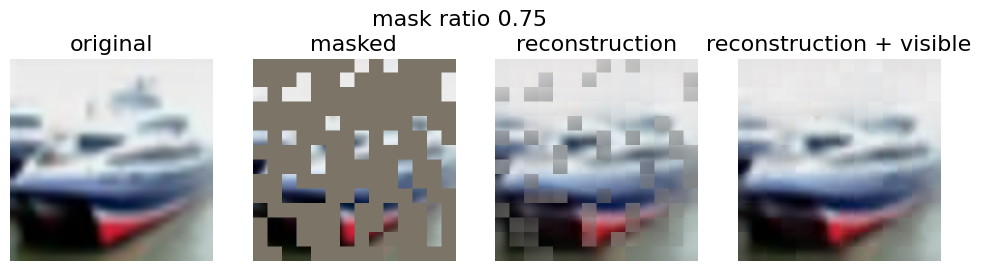

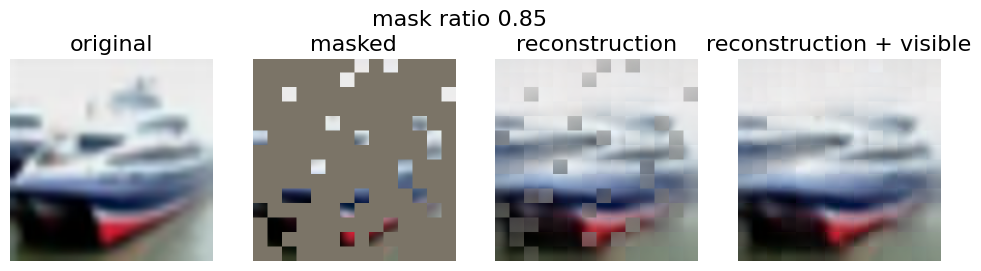

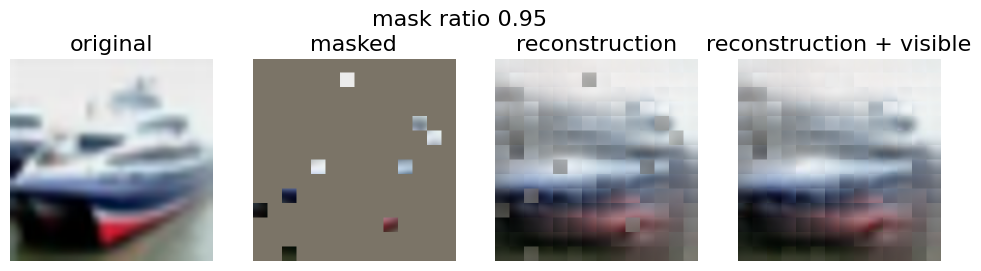

In [12]:
# example code reconstruct a few images from the test set
dataset_test = torchvision.datasets.CIFAR10(root=data_path, train=False, transform=None, download=True)
img_1 = dataset_test[0][0]
img_2 = dataset_test[1][0]

final_checkpoint = os.path.join(output_dir, f'checkpoint-{epochs}.pth')
mask_ratios = [0.5, 0.75, 0.85, 0.95]

# visualize reconstructions...
for img in (img_1, img_2):
    for r in mask_ratios:
        visualize(img, final_checkpoint, mask_ratio=r, title=f'mask ratio {r}')

In [13]:
# Quantitative check for the mask-ratio question: mean squared error on the masked patches
# (normalised pixel space, the same quantity as the training loss) over the first test images.
# The masks are seeded identically for every checkpoint, so the numbers are comparable.
eval_transform = transforms.Compose([
    transforms.Resize((input_size, input_size), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
n_eval_images = 512
eval_subset = torch.utils.data.Subset(
    torchvision.datasets.CIFAR10(root=data_path, train=False, transform=eval_transform, download=True),
    range(n_eval_images))


@torch.no_grad()
def masked_reconstruction_mse(chkpt_path, ratios, model_builder=None, eval_seed=0):
    model_eval = (model_builder or build_model)()
    model_eval.load_state_dict(torch.load(chkpt_path, map_location='cpu')['model'], strict=True)
    model_eval.to(device).eval()
    loader = torch.utils.data.DataLoader(eval_subset, batch_size=128, shuffle=False)
    results = {}
    for r in ratios:
        torch.manual_seed(eval_seed)
        total, n = 0.0, 0
        for x, _ in loader:
            x = x.to(device)
            loss, _, _ = model_eval(x, mask_ratio=r)
            total += loss.item() * x.shape[0]
            n += x.shape[0]
        results[r] = total / n
    return results


mse_by_ratio = masked_reconstruction_mse(final_checkpoint, mask_ratios)
print('Masked-patch MSE of the trained MAE (lower is better):')
for r, v in mse_by_ratio.items():
    print(f'  mask ratio {r:.2f} | visible patches {int(196 * (1 - r)):3d} | MSE {v:.4f}')

Masked-patch MSE of the trained MAE (lower is better):
  mask ratio 0.50 | visible patches  98 | MSE 0.0382
  mask ratio 0.75 | visible patches  49 | MSE 0.1039
  mask ratio 0.85 | visible patches  29 | MSE 0.1950
  mask ratio 0.95 | visible patches   9 | MSE 0.5080


**Question**

We trained the model with a mask ratio of 0.75. Now, experiment with reconstructing images using different mask ratios, such as 0.5, 0.75, 0.85, and 0.95.
* What difference/variations do you observe in the reconstruction quality?
* What differences do you see with especially very high masking ratios?



**Answer**

Measured masked-patch MSE of the 20-epoch model (512 test images, identical masks):

| mask ratio | visible patches | masked-patch MSE |
|---|---|---|
| 0.50 | 98 | 0.038 |
| 0.75 | 49 | 0.104 |
| 0.85 | 29 | 0.195 |
| 0.95 | 9 | 0.508 |

* **The quality degrades smoothly at first and then sharply.** The error almost triples from 0.5 to 0.75, roughly doubles again at 0.85, and is 13× the 0.5 value at 0.95. With 0.5, the "reconstruction + visible" images of the cat and the ship are almost identical to the originals and only slightly softer. Every masked patch has visible neighbours, and the upsampled CIFAR-10 images are very smooth at the 16×16 patch scale (one patch ≈ 2.3×2.3 original pixels), so the model mostly interpolates.
* **At 0.75 (training ratio) and 0.85:** The global layout, colours and object outline are still correct (orange background, blue cloth, cat head; white sky, blue-red hull), but fine detail is lost. The cat's face and fur become a soft blur and the ship's windows disappear. This blur is expected from an MSE objective: when the model is uncertain it predicts the *mean* of the plausible patches.
* **Very high ratio (0.95):** With only 9 visible patches, the model reconstructs only a coarse colour layout: an orange top and blue bottom for the cat, a white top with a dark/red band for the ship. Neither object is recognisable any more. The reconstruction is a set of smooth colour gradients, close to an "average image" consistent with the few visible colours. The model was trained at 0.75 and has never had to work from so little context.
* **Visible positions are not reconstructed.** In the raw "reconstruction" column, the positions of the *visible* patches appear as flat grey blocks. The loss is computed only on masked patches, so the decoder never learns to output anything meaningful there. Only the pasted composite looks complete.


**Question**

By now, you should have a good understanding of how MAE functions.

* If you were to utilize the MAE encoder for a downstream task (such as bird classification), how effective do you think it would be?
* In which downstream tasks do you expect the representations learned by MAE to perform particularly well?
* How does MAE compare against other self-supervised learning methods you are familiar with? Does it present any advantages or disadvantages?




**Answer**

* **Downstream bird classification.** With a *frozen* encoder and a linear classifier, MAE features are only moderately good. The MAE paper shows that linear-probing accuracy is clearly below that of contrastive methods, because pixel reconstruction does not force the features to be linearly separable by class. With *fine-tuning* the whole encoder, MAE pre-training is very effective; the paper reports the best fine-tuning results among the compared methods. Our model is small, trained for only 20 epochs on upsampled 32×32 CIFAR-10 images, and has never seen fine bird details. For fine-grained species classification I would therefore expect weak linear-probe accuracy, while fine-tuning should still give a useful starting point compared with random initialisation.
* **Tasks where MAE representations do well.** Tasks that need local and spatial information: semantic segmentation, object detection and instance segmentation (the paper reports gains on COCO and ADE20K), depth estimation, inpainting/restoration, and generally any task where the encoder is fine-tuned. The method is also useful in domains with many unlabeled images but few labels, such as medical or satellite imagery, because it needs no labels and no domain-specific augmentations.
* **Comparison with other SSL methods (SimCLR/MoCo/BYOL/DINO).** *Advantages:* MAE needs no negative pairs, so it does not depend on large batches or memory queues. It cannot collapse, because it has a concrete reconstruction target. It relies only on cropping and flipping rather than carefully tuned colour or blur augmentations. The encoder processes only 25% of the tokens, so pre-training is about 3× cheaper, and the method scales well to large ViTs. *Disadvantages:* the features are less semantic and less invariant, so linear probing is weaker and fine-tuning is usually required. Reconstructing pixels spends capacity on low-level texture and colour. Long pre-training (hundreds of epochs) is still needed, and token masking is natural for ViTs but awkward for CNNs. Contrastive methods, on the other hand, directly learn invariance to their augmentations, which suits classification but depends on choosing the right augmentations.

## Positional encoding

**Question**

As we saw above, both the encoder and decoder rely on positional encodings added to the tokens before processing them.
- What does positional encoding do, and why is it important?
- We implemented it as a trainable parameter, but does it need to be trainable? What are the alternatives?
- Can we eliminate positional encodings entirely?

**Answer**

* **What it does and why it matters.** Self-attention and the token-wise MLP are *permutation-equivariant*: if the input tokens are shuffled, the outputs are shuffled in the same way. Without additional information, a ViT therefore sees a *set* of patches, not a 2D grid, and cannot tell where a patch came from or which patches are neighbours. A positional encoding adds a position-dependent vector to each token, giving the model the spatial layout. In MAE this is essential for the decoder: all mask tokens are the same learned vector, so their positional encoding is the *only* information about which patch each one has to reconstruct.
* **Does it need to be trainable?** No. The original transformer uses fixed sinusoidal encodings, and MAE itself uses *fixed 2D sine-cosine* encodings; in the ViT paper, learned and fixed encodings perform almost equally well. Other options are relative position encodings or attention biases (Swin, T5, ALiBi), rotary embeddings (RoPE), and conditional encodings produced by a convolution on the token grid (CPVT). Fixed encodings and relative schemes also adapt more easily to new resolutions.
* **Can we remove it completely?** For whole-image classification, a ViT without positional information still works to some extent, because a "bag of patches" often identifies the class; the ViT paper reports only a moderate drop in accuracy. For MAE reconstruction it cannot be removed. Without positions the decoder receives identical mask tokens and has no information to tell them apart. Because of permutation equivariance, every masked position gets *exactly the same* prediction, so the network cannot put the missing content in the right place. Position information would have to come from another source, such as convolutions with padding or relative-position attention.



Start training for 10 epochs -> ./output_dir/pos_fixed


Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 1 done. Time: 4.264m - mean train loss: 0.404 (last batch 0.174). Saved model checkpoint to: ./output_dir/pos_fixed/checkpoint-1.pth


Training:   0%|          | 0/781 [00:00<?, ?it/s]

Training:   0%|          | 0/781 [00:00<?, ?it/s]

... (17 outputs left out)

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Training:   0%|          | 0/781 [00:00<?, ?it/s]

Epoch 10 done. Time: 4.23m - mean train loss: 0.812 (last batch 0.74). Saved model checkpoint to: ./output_dir/pos_none/checkpoint-10.pth
Training time 0:42:20


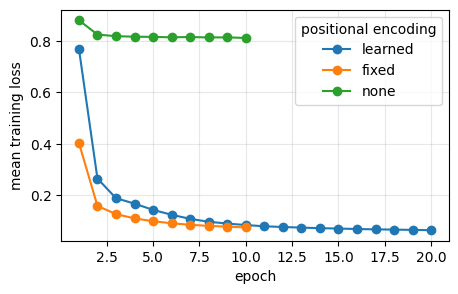

/tmp/ipykernel_48/1236116758.py:20: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.imshow(torch.clip((image * imagenet_std + imagenet_mean) * 255, 0, 255).int())


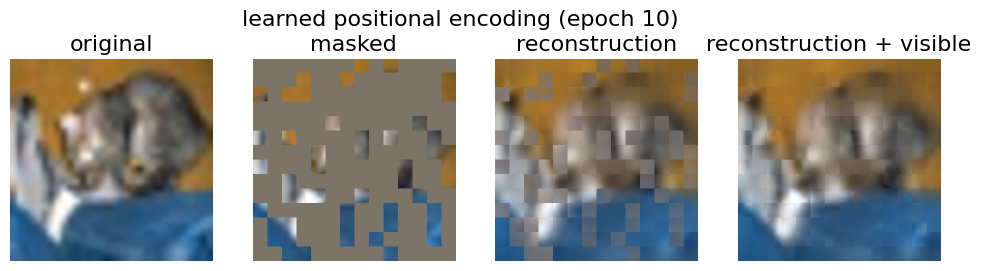

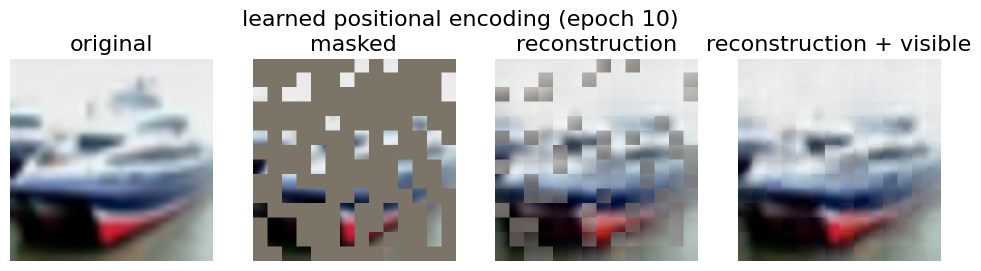

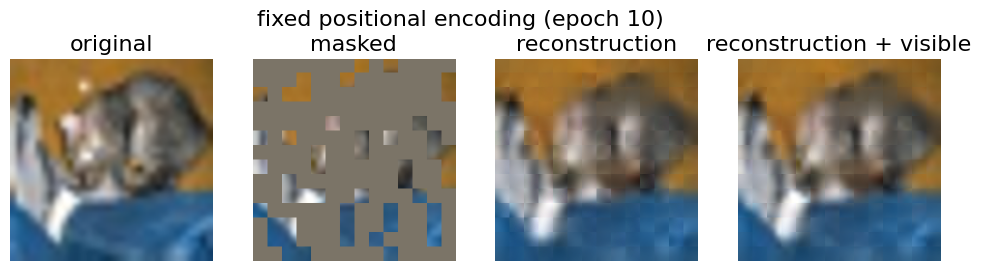

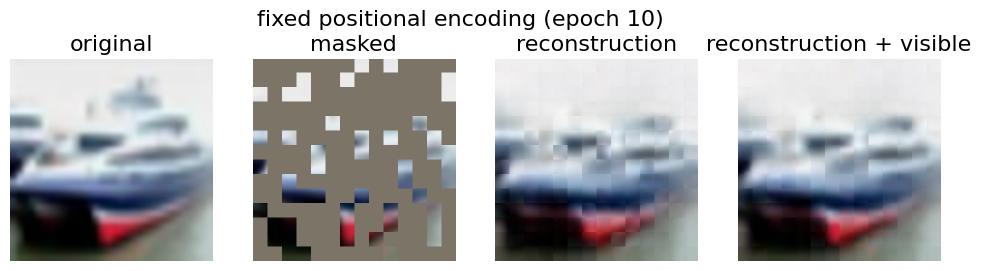

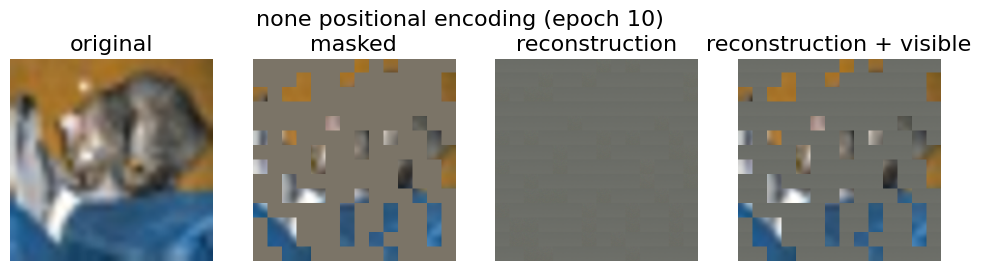

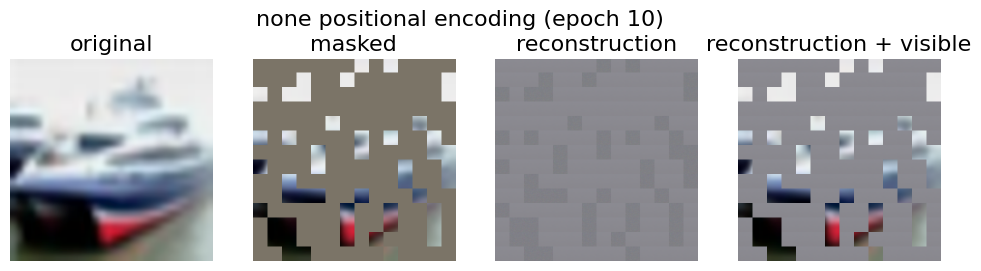

Masked-patch MSE after 10 epochs (lower is better):
pos. encoding | r=0.50 | r=0.75 | r=0.85 | r=0.95
learned       | 0.0541 | 0.1251 | 0.2210 | 0.5496
fixed         | 0.0483 | 0.1135 | 0.2069 | 0.5147
none          | 0.8761 | 0.8802 | 0.8918 | 0.9434


In [14]:
"""
    TODO: modify the implementation of positional encodings.
    Try two different variants:
        1) fixed, non-trainable positional encodings
        2) eliminate the positional encodings entirely, such that no information about the location of patches are processed by the model
    Repeat training with these two configs and reconstruct the images.
"""

def get_2d_sincos_pos_embed(embed_dim, grid_size):
    """Fixed 2D sine-cosine positional encoding (as used in the MAE paper).
    Half of the channels encode the row, the other half the column, each with the
    1D transformer encoding sin/cos(pos / 10000^(2i/d)). Returns (grid_size**2, embed_dim)."""
    assert embed_dim % 4 == 0

    def sincos_1d(dim, pos):
        omega = np.arange(dim // 2, dtype=np.float64) / (dim / 2.)
        omega = 1. / 10000 ** omega                      # (dim/2,)
        out = np.einsum('m,d->md', pos.reshape(-1), omega)  # (M, dim/2)
        return np.concatenate([np.sin(out), np.cos(out)], axis=1)

    grid_h, grid_w = np.meshgrid(np.arange(grid_size, dtype=np.float64),
                                 np.arange(grid_size, dtype=np.float64), indexing='ij')
    # row-major order, the same order PatchEmbed uses for the tokens
    emb = np.concatenate([sincos_1d(embed_dim // 2, grid_h), sincos_1d(embed_dim // 2, grid_w)], axis=1)
    return emb.astype(np.float32)


class MAEPosVariant(MaskedAutoencoderViT):
    """MAE whose encoder and decoder positional encodings are
       - 'learned': trainable, randomly initialised (the model used above),
       - 'fixed'  : 2D sin-cos values that are not trained (requires_grad=False),
       - 'none'   : all zeros and not trained, i.e. no location information at all."""
    def __init__(self, pos_mode='learned', **kwargs):
        super().__init__(**kwargs)
        assert pos_mode in ('learned', 'fixed', 'none')
        self.pos_mode = pos_mode
        if pos_mode == 'learned':
            return
        grid = int(self.patch_embed.num_patches ** .5)
        with torch.no_grad():
            for pe in (self.pos_embed, self.decoder_pos_embed):
                if pos_mode == 'fixed':
                    pe.copy_(torch.from_numpy(get_2d_sincos_pos_embed(pe.shape[-1], grid)).unsqueeze(0))
                else:
                    pe.zero_()
                pe.requires_grad_(False)


def build_model_variant(pos_mode, **kwargs):
    return MAEPosVariant(pos_mode=pos_mode,
        patch_size=16, embed_dim=384, depth=12, num_heads=6,
        decoder_embed_dim=512, decoder_depth=8, decoder_num_heads=16,
        mlp_ratio=4, **kwargs)


# checks: fixed encodings are deterministic and distinct per position; 'none' carries no position
_fixed = build_model_variant('fixed')
assert not _fixed.pos_embed.requires_grad and not _fixed.decoder_pos_embed.requires_grad
assert torch.allclose(_fixed.pos_embed, build_model_variant('fixed').pos_embed)
assert torch.unique(_fixed.pos_embed[0], dim=0).shape[0] == 196
assert torch.count_nonzero(build_model_variant('none').pos_embed) == 0
del _fixed

# Train both variants with the same data, seed, optimiser and loop as the baseline.
# 10 epochs each by default to save Colab time; the baseline is compared at the same epoch
# using its saved checkpoint (save_interval=1 above keeps every epoch).
ablation_epochs = min(10, epochs)
pos_runs = {'learned': output_dir}
for pos_mode in ('fixed', 'none'):
    run_dir = os.path.join(os.path.dirname(output_dir), f'pos_{pos_mode}')
    pos_runs[pos_mode] = run_dir
    loss_history[pos_mode] = train_mae(build_model_variant(pos_mode, img_size=input_size), run_dir,
                                       ablation_epochs, save_interval=ablation_epochs)

ckpt = lambda mode: os.path.join(pos_runs[mode], f'checkpoint-{ablation_epochs}.pth')
assert os.path.exists(ckpt('learned')), 'baseline checkpoint for this epoch is missing (set save_interval=1)'

# training curves
plt.figure(figsize=(5, 3))
for mode, hist in loss_history.items():
    plt.plot(range(1, len(hist) + 1), hist, marker='o', label=mode)
plt.xlabel('epoch'); plt.ylabel('mean training loss'); plt.legend(title='positional encoding')
plt.grid(alpha=0.3); plt.show()

# reconstructions at the training mask ratio
for mode in ('learned', 'fixed', 'none'):
    for img in (img_1, img_2):
        visualize(img, ckpt(mode), mask_ratio=0.75, model_builder=partial(build_model_variant, mode),
                  title=f'{mode} positional encoding (epoch {ablation_epochs})')

# masked-patch MSE on the same 512 test images with identical masks
print(f'Masked-patch MSE after {ablation_epochs} epochs (lower is better):')
print('pos. encoding | ' + ' | '.join(f'r={r:.2f}' for r in mask_ratios))
for mode in ('learned', 'fixed', 'none'):
    res = masked_reconstruction_mse(ckpt(mode), mask_ratios, model_builder=partial(build_model_variant, mode))
    print(f'{mode:13s} | ' + ' | '.join(f'{res[r]:.4f}' for r in mask_ratios))

**Question**

Is there any difference in the reconstruction quality?

**Answer**

Yes. Measured masked-patch MSE after 10 epochs each (same data, seed, optimiser and masks):

| positional encoding | r = 0.50 | r = 0.75 | r = 0.85 | r = 0.95 | final training loss |
|---|---|---|---|---|---|
| learned | 0.054 | 0.125 | 0.221 | 0.550 | 0.084 |
| fixed 2D sin-cos | **0.048** | **0.114** | **0.207** | **0.515** | 0.075 |
| none | 0.876 | 0.880 | 0.892 | 0.943 | 0.812 |

* **Fixed vs learned:** The two are close, but the fixed sin-cos encoding is consistently better at every mask ratio (about 9% lower error at 0.75) and has a lower training loss. After 10 epochs, a fixed encoding that already gives every patch a distinct, smoothly varying code helps, while learned embeddings must first discover the 2D grid from random initialisation. The figures show this too: the fixed model gives slightly sharper, more coherent cat and ship reconstructions. Its raw predictions even fill in the visible positions plausibly, whereas the learned model leaves grey blocks there. The gap would probably shrink with longer training; the MAE paper also uses fixed sin-cos.
* **No positional encoding:** Reconstruction fails completely. The raw reconstruction is a uniform grey image, and every masked patch receives the *same* flat grey prediction, so the composite is just the visible patches on a grey background. The MSE (≈0.88) barely depends on the mask ratio, and the training loss stalls at about 0.81 (from 0.88 after epoch 1). This is exactly what the architecture predicts: the mask tokens are identical and the decoder is permutation-equivariant, so it cannot distinguish masked positions. The best constant prediction is roughly the dataset's mean colour, which in normalised space is this grey.


## Patch size

**Question**

In our ViT implementation, we used a patch size of 16.

* How do you think smaller or larger patch sizes affect reconstruction quality (or performance in general) respectively? What are the reasons behind this?
* What effect do patch sizes have on computational requirements? Why?


**Answer**

* **Effect on reconstruction and performance.** *Smaller patches* (e.g. 8×8) produce more tokens, each describing a smaller region. Reconstructions are sharper and preserve more detail, and each masked patch is closer to visible pixels, so the task is easier. When the patches are too small, however, the pretext task can be solved by low-level interpolation from neighbouring pixels, so the encoder learns less semantic features, unless the mask ratio is increased. *Larger patches* (e.g. 32×32) remove whole object parts, so the task is harder and more semantic, but the reconstruction is coarser and blurrier. The model also has fewer tokens, with less spatial resolution, to describe the image, which hurts dense downstream tasks.
* **Computational requirements.** The number of tokens is N = (H/p)². Self-attention costs O(N²·d) time and O(N²) memory per layer for the attention matrix, while the MLPs cost O(N·d²). Halving the patch size gives 4× more tokens, so the attention cost grows about 16× and the MLP cost 4×. The patch-embedding convolution has roughly the same cost for any p, about H·W·3·d multiply-adds, and the output layer of the decoder gets wider (p²·3), but these terms are small. Larger patches are therefore much cheaper. MAE reduces the encoder cost further by processing only the (1 − mask ratio)·N visible tokens, which makes encoder attention about 16× cheaper at 75% masking.


**Question**

Finally, how much time did it take you to complete this practical? It helps us balance the difficulty of the different practicals.

**Answer** 5 hours 35 minutes (running time 4 hours)


In [15]:
print(f'Time since the first code cell was run: {datetime.timedelta(seconds=int(time.time() - notebook_started_at))}')

Time since the first code cell was run: 3:59:54
